In [51]:
from pathlib import Path
import altair as alt
import pandas as pd
import pycountry

DATA_DIR = Path("data/raw")
ISCO = ["Managers", "Professionals", "Technicians & associate professionals",
        "Clerical support workers", "Service & sales workers", "Skilled agricultural workers",
        "Craft & related trades", "Plant & machine operators", "Elementary occupations"]
ISCO_ORDER = list(ISCO08.values())
INCOME = ["Low income", "Lower middle income", "Upper middle income", "High income"]
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CLERICAL = "Clerical support workers"
alt.renderers.enable("png")  # show charts as static images in the notebook

@alt.theme.register("course", enable=True)
def theme():
    gray = {"labelColor": "#52514e", "titleColor": "#52514e"}
    return {"config": {"background": "#fcfcfb", "view": {"stroke": None},
                       "title": {"anchor": "start", "subtitleColor": "#52514e"},
                       "axis": {**gray, "gridColor": "#e8e7e3", "domainColor": "#e8e7e3"},
                       "legend": gray}}

### ILOSTAT (International Labour Organization)

In [ ]:
## Load and Clean ILOSTAT
occ = pd.read_csv(DATA_DIR / "ilostat_emp_occ_1digit.csv", low_memory=False)
occ = occ[occ["classif1"].str.match(r"^OCU_ISCO08_[1-9]$")].rename(
    columns={"ref_area": "iso3", "time": "year", "obs_value": "emp"})
occ = occ[occ["source"] == occ.groupby(["iso3", "year"])["source"].transform("first")]
occ["occupation"] = occ["classif1"].str[-1].astype(int).map(lambda i: ISCO[i - 1])
occ["sex"] = occ["sex"].map({"SEX_T": "Total", "SEX_M": "Men", "SEX_F": "Women"})
occ["share"] = occ["emp"] / occ.groupby(["iso3", "year", "sex"])["emp"].transform("sum")

# Country names and numeric codes (for the map), plus World Bank income groups
countries = {c.alpha_3: (getattr(c, "common_name", c.name), int(c.numeric)) for c in pycountry.countries}
occ["country"] = occ["iso3"].map(lambda c: countries.get(c, (c, None))[0])
occ["iso_num"] = occ["iso3"].map(lambda c: countries.get(c, (c, None))[1])
occ = occ.merge(pd.read_csv(DATA_DIR / "worldbank_countries.csv")[["iso3", "income_group"]],
                on="iso3", how="inner")

latest = occ[occ["year"] == occ.groupby("iso3")["year"].transform("max")]
total = latest[latest["sex"] == "Total"]

In [52]:
MAP_OCCUPATION = CLERICAL
m = total[total["occupation"] == MAP_OCCUPATION]
mapped = m[["iso_num", "share"]].astype({"iso_num": int})
yr_min, yr_max = m["year"].min(), m["year"].max()   # needs a year column in `total`

world = alt.topo_feature("https://cdn.jsdelivr.net/npm/vega-datasets@v1.29.0/data/world-110m.json", "countries")

gray = alt.Chart(world).mark_geoshape(fill="#e8e7e3", stroke="white", strokeWidth=0.5)
shares = (
    alt.Chart(world).mark_geoshape(stroke="white", strokeWidth=0.5)
    .transform_lookup(lookup="id", from_=alt.LookupData(mapped, "iso_num", ["share"]))
    .transform_filter("isValid(datum.share)")
    .encode(color=alt.Color(
        "share:Q", title="Share of employment in clerical jobs",
        scale=alt.Scale(type="threshold", domain=[0.04, 0.08, 0.12, 0.16], range=BLUES[1:6]),
        legend=alt.Legend(format=".0%", orient="bottom", direction="horizontal",
                          titleLimit=300, gradientLength=300)))
)
map_chart = (gray + shares).transform_filter("datum.id != 10").project("equalEarth").properties(
    width=760, height=400,
    title=alt.Title(
        "Clerical jobs, the work most exposed to generative AI, are concentrated in richer countries",
        subtitle=[f"Share of employment in clerical support occupations (ISCO-08 group 4), latest year {yr_min}–{yr_max}.",
                  "Gray = no ISCO-08 data (e.g. Canada and China use other classifications or don't report)."]))
map_chart

Path("figures").mkdir(exist_ok=True)
map_chart.save("figures/clerical_map.png", scale_factor=2)

In [53]:
n = total.groupby("income_group")["iso3"].nunique()
inc["income_label"] = inc["income_group"] + " (n=" + inc["income_group"].map(n).astype(str) + ")"
label_order = [f"{g} (n={n[g]})" for g in INCOME if g in n]

bold_clerical = {"condition": {"test": f"datum.value == '{CLERICAL}'", "value": "bold"}, "value": "normal"}

base = alt.Chart(inc).encode(
    x=alt.X("income_label:N", sort=label_order, title=None,
            axis=alt.Axis(labelAngle=0, orient="top", ticks=False, domain=False)),
    y=alt.Y("occupation:N", sort=ISCO, title=None,
            axis=alt.Axis(ticks=False, domain=False, labelFontWeight=bold_clerical)))

heatmap = (
    base.mark_rect(stroke="white", strokeWidth=2).encode(
        color=alt.Color("share:Q", legend=None,
                        scale=alt.Scale(range=BLUES, domain=[0, 0.35], clamp=True)))
    + base.mark_text(fontSize=12).encode(
        text=alt.Text("share:Q", format=".0%"),
        color=alt.condition("datum.share > 0.22", alt.value("white"), alt.value("#0b0b0b")))
).properties(
    width=560, height=320,
    title=alt.Title(
        "As income rises, work shifts from farms to offices",
        subtitle=["Share of employment by occupation; each column sums to 100%. Bold = clerical work, the group most exposed to GenAI.",
                  "Countries with ISCO-08 data, latest year available, weighted by workforce size."]))
heatmap
heatmap.save("figures/occupation_heatmap.png", scale_factor=2)

In [55]:
y = alt.Y("country:N", sort=alt.SortField("gap", order="descending"), title=None,
          axis=alt.Axis(ticks=False, domain=False))
x_scale = alt.Scale(domain=[0, 0.30])

rule = alt.Chart(cler).mark_rule(color="#c9c8c2", strokeWidth=2).encode(
    y=y, x=alt.X("Men:Q", scale=x_scale), x2="Women:Q")

dots = alt.Chart(cler).transform_fold(["Women", "Men"], as_=["sex", "share"]).mark_circle(size=90, opacity=1).encode(
    y=y,
    x=alt.X("share:Q", scale=x_scale,
            title="Share of employed women / men working in clerical jobs",
            axis=alt.Axis(format=".0%", values=[0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30])),
    color=alt.Color("sex:N", title=None, scale=alt.Scale(domain=["Women", "Men"], range=COLORS[:2]),
                    legend=alt.Legend(orient="top")))

gap_labels = alt.Chart(cler).transform_calculate(
    gap_label="'+' + format(datum.gap * 100, '.0f') + ' pts'"
).mark_text(align="left", dx=8, fontSize=10, color="#52514e").encode(
    y=y, x=alt.X("Women:Q", scale=x_scale), text="gap_label:N")

dumbbell = (rule + dots + gap_labels).properties(
    width=500, height=alt.Step(18),
    title=alt.Title(
        "Women are far more likely than men to work in clerical jobs",
        subtitle=["The 30 economies with the largest gap, among those with 1M+ workers. Latest year available.",
                  "Clerical work is the occupation group most exposed to generative AI (ILO, 2025)."]))
dumbbell.save("figures/sex_clerical_jobs.png", scale_factor=2)

In [56]:
years = occ[(occ["occupation"] == CLERICAL) & (occ["sex"] == "Total")].groupby(
    ["income_group", "iso3", "country"])["year"].agg(["nunique", "min", "max"]).reset_index()
print(years.sort_values(["income_group", "nunique"], ascending=[True, False])
      .groupby("income_group").head(3))

            income_group iso3         country  nunique   min   max
2            High income  AUS       Australia       16  2010  2025
9            High income  CHE     Switzerland       16  2010  2025
22           High income  GBR  United Kingdom       16  2010  2025
72            Low income  RWA          Rwanda       11  2012  2025
68            Low income  MLI            Mali       10  2013  2024
77            Low income  UGA          Uganda        6  2012  2021
82   Lower middle income  BOL         Bolivia       15  2011  2025
88   Lower middle income  EGY           Egypt       14  2010  2024
94   Lower middle income  KGZ      Kyrgyzstan       14  2010  2023
130  Upper middle income  COL        Colombia       16  2010  2025
139  Upper middle income  GEO         Georgia       16  2010  2025
151  Upper middle income  MDA         Moldova       16  2010  2025


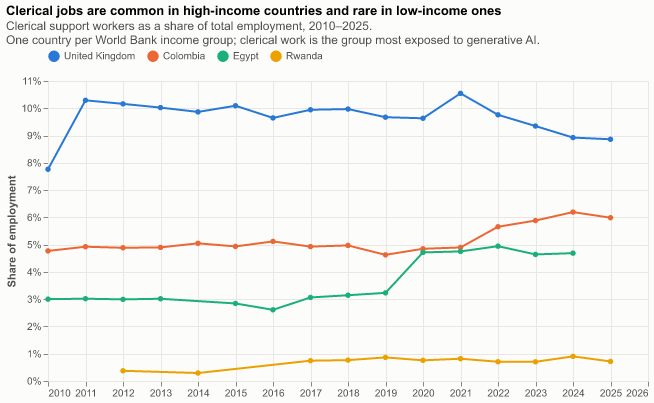

In [58]:
COUNTRIES = ["GBR", "COL", "EGY", "RWA"]   # one per income group, high to low
ts = occ[(occ["occupation"] == CLERICAL) & (occ["sex"] == "Total") & occ["iso3"].isin(COUNTRIES)]
order = ts.drop_duplicates("iso3").set_index("iso3").loc[COUNTRIES, "country"].tolist()

line_chart = alt.Chart(ts).mark_line(point=True, strokeWidth=2).encode(
    x=alt.X("year:Q", title=None, axis=alt.Axis(format="d", tickMinStep=1)),
    y=alt.Y("share:Q", title="Share of employment", axis=alt.Axis(format=".0%")),
    color=alt.Color("country:N", title=None, sort=order,
                    scale=alt.Scale(domain=order, range=COLORS), legend=alt.Legend(orient="top")),
).properties(
    width=600, height=300,
    title=alt.Title("Clerical jobs as a share of employment",
                    subtitle="One country from each World Bank income group (high to low), chosen for the longest ISCO-08 series"))
line_chart = line_chart.properties(
    title=alt.Title(
        "Clerical jobs are common in high-income countries and rare in low-income ones",
        subtitle=["Clerical support workers as a share of total employment, 2010–2025.",
                  "One country per World Bank income group; clerical work is the group most exposed to generative AI."]))
line_chart.save("figures/clerical_lines.png", scale_factor=2)
line_chart

In [23]:
from pathlib import Path
import altair as alt
import pandas as pd

DATA_DIR = Path("data/raw")
ACTIVITY = "Manufacturing"   # which industry to chart (see the printout below for options)
SIZE = "10 or more"          # which firm size class to chart
BLUE, GRAY, ORANGE = "#2a78d6", "#a3a29c", "#eb6834"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
alt.renderers.enable("png")

@alt.theme.register("course", enable=True)
def theme():
    gray = {"labelColor": "#52514e", "titleColor": "#52514e"}
    return {"config": {"background": "#fcfcfb", "view": {"stroke": None},
                       "title": {"anchor": "start", "subtitleColor": "#52514e"},
                       "axis": {**gray, "gridColor": "#e8e7e3", "domainColor": "#e8e7e3"},
                       "legend": gray}}

In [61]:
import numpy as np
import pandas as pd

ACTIVITY = "Total - all activities"
SIZE = "10 or more"

ai = pd.read_csv(DATA_DIR / "oecd_ict_business_ai.csv")
ai = ai[ai["MEASURE"] == "G14_B"].rename(columns={
    "REF_AREA": "iso3", "Reference area": "country", "Economic activity": "activity",
    "Employment size class": "size", "TIME_PERIOD": "year"})

# Drop rows with no year (blank/footnote rows) before casting to int
ai = ai.dropna(subset=["year"])
ai["year"] = ai["year"].astype(int)
ai["share"] = ai["OBS_VALUE"] / 100
ai = ai[["iso3", "country", "activity", "size", "year", "share"]]

print("Industries:", sorted(ai["activity"].unique()))
print("Firm sizes:", sorted(ai["size"].unique()))
print("Years:", sorted(ai["year"].unique()))

# Latest year per country with actual data, for the chosen industry and firm size
sel = ai[(ai["activity"] == ACTIVITY) & (ai["size"] == SIZE)].dropna(subset=["share"])
assert len(sel), "No rows for this ACTIVITY/SIZE - check the printed labels above"

latest = sel[sel["year"] == sel.groupby("iso3")["year"].transform("max")].copy()
assert not latest.duplicated("iso3").any(), latest[latest.duplicated("iso3", keep=False)]

newest = latest["year"].max()
# Flag countries whose latest data is older than everyone else's, e.g. "Brazil (2021)"
latest["label"] = latest["country"].where(latest["year"] == newest,
                                          latest["country"] + " (" + latest["year"].astype(str) + ")")

# EU code may be "EU27" or "EU27_2020" depending on the export
is_eu = latest["iso3"].str.startswith("EU27")
latest.loc[is_eu, "label"] = "EU-27 average"
latest["group"] = np.where(is_eu, "EU average", "Country")

Industries: ['Accommodation and food service activities', 'Administrative and support service activities', 'Construction', 'Financial and insurance activities', 'Information and communication', 'Manufacturing', 'Professional, scientific and technical activities', 'Real estate activities', 'Retail trade, except of motor vehicles and motorcycles', 'Total - all activities', 'Transportation and storage', 'Wholesale trade, except of motor vehicles and motorcycles']
Firm sizes: ['10 or more', '250 or more', 'From 10 to 49', 'From 50 to 249']
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


In [63]:
ranked = latest.sort_values("share", ascending=False)["label"].tolist()
bars = alt.Chart(latest).encode(
    y=alt.Y("label:N", sort=ranked, title=None, axis=alt.Axis(ticks=False, domain=False)),
    x=alt.X("share:Q", title="Share of businesses using AI", axis=alt.Axis(format=".0%")))
bar_chart = (
    bars.mark_bar(cornerRadiusEnd=4, height=14).encode(
        color=alt.Color("group:N", scale=alt.Scale(domain=["Country", "EU average"], range=[BLUE, GRAY]),
                        legend=None))
    + bars.mark_text(align="left", dx=4, fontSize=11, color="#52514e").encode(text=alt.Text("share:Q", format=".0%"))
).properties(width=480, height=alt.Step(20),
             title=alt.Title(f"Share of businesses using AI: {ACTIVITY.lower()}",
                             subtitle=f"Firms with {SIZE} employees, {newest} unless noted. Gray = EU average"))
bar_chart
bar_chart.save("figures/business_ai.png", scale_factor=2)

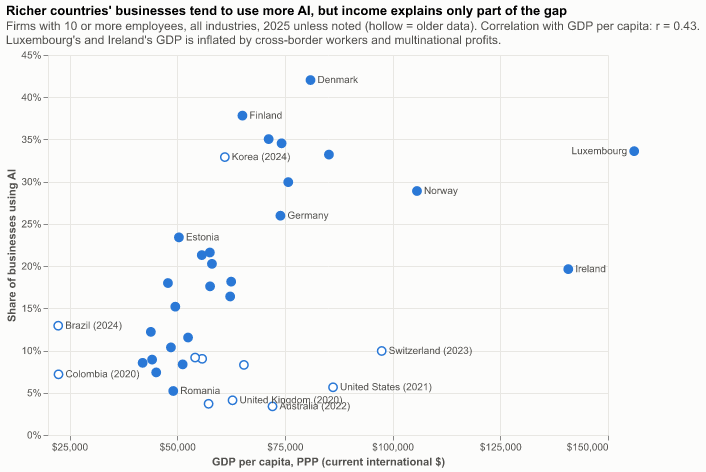

In [67]:
wdi = pd.read_csv(DATA_DIR / "worldbank_wdi.csv")
gdp = (wdi[(wdi["indicator"] == "gdp_per_capita_ppp") & wdi["value"].notna()]
       .sort_values("year").groupby("iso3").last()["value"].rename("gdp"))
scatter_df = (latest[~latest["iso3"].str.startswith(("EU27", "OECD"))]
              .join(gdp, on="iso3").dropna(subset=["gdp"]))
scatter_df["recent"] = scatter_df["year"] == newest

# Strength of the relationship, for the subtitle
r = np.corrcoef(scatter_df["gdp"], scatter_df["share"])[0, 1]

LABEL = ["Denmark", "Finland", "Korea", "Germany", "Norway", "Ireland", "Brazil", "Colombia",
         "United States", "United Kingdom", "Australia", "Switzerland", "Romania", "Estonia"]
scatter_df["show"] = scatter_df["country"].isin(LABEL)

x = alt.X("gdp:Q", title="GDP per capita, PPP (current international $)",
          scale=alt.Scale(domain=[20_000, 150_000], nice=False),
          axis=alt.Axis(format="$,.0f", values=[25_000, 50_000, 75_000, 100_000, 125_000, 150_000]))
y = alt.Y("share:Q", title="Share of businesses using AI",
          scale=alt.Scale(domain=[0, 0.45]), axis=alt.Axis(format=".0%"))
base = alt.Chart(scatter_df).encode(x=x, y=y)

dots = base.mark_point(size=70, filled=True, stroke=BLUE, strokeWidth=1.5, opacity=1).encode(
    fill=alt.condition("datum.recent", alt.value(BLUE), alt.value("white")))
labels = base.transform_filter("datum.show").mark_text(
    align="left", dx=7, fontSize=10, color="#52514e").encode(text="label:N")
lux = base.transform_filter("datum.country == 'Luxembourg'").mark_text(
    align="right", dx=-7, fontSize=10, color="#52514e").encode(text="label:N")

scatter = (dots + labels + lux).properties(
    width=560, height=380,
    title=alt.Title(
        "Richer countries' businesses tend to use more AI, but income explains only part of the gap",
        subtitle=[f"Firms with {SIZE} employees, all industries, {newest} unless noted (hollow = older data). "
                  f"Correlation with GDP per capita: r = {r:.2f}.",
                  "Luxembourg's and Ireland's GDP is inflated by cross-border workers and multinational profits."]))
scatter.save("figures/gdp_ai_scatter.png", scale_factor=2)
scatter

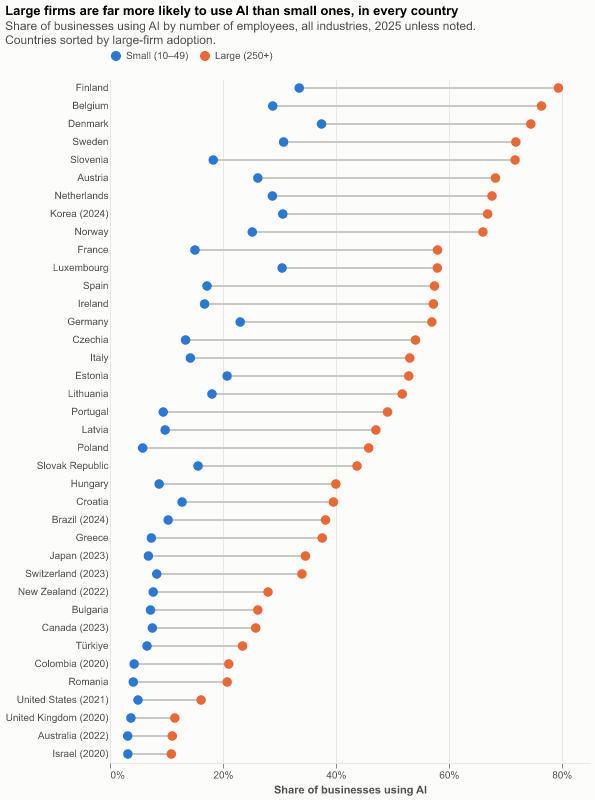

In [68]:
small, large = "From 10 to 49", "250 or more"
S, L = "Small (10–49)", "Large (250+)"

# Exclude aggregates (EU-27, OECD) so only countries are compared
by_size = ai[(ai["activity"] == ACTIVITY) & ai["size"].isin([small, large])
             & ~ai["iso3"].str.startswith(("EU27", "OECD"))].dropna(subset=["share"])

# Keep only years where both size classes are present, then the latest such year per country
by_size = (by_size.pivot_table(index=["country", "year"], columns="size", values="share")
           .dropna().reset_index())
by_size = by_size[by_size["year"] == by_size.groupby("country")["year"].transform("max")]

by_size = by_size.rename(columns={small: S, large: L})
size_newest = by_size["year"].max()   # own name, so it doesn't overwrite `newest` used by other charts
by_size["label"] = by_size["country"].where(by_size["year"] == size_newest,
                                            by_size["country"] + " (" + by_size["year"].astype(str) + ")")
order = by_size.sort_values(L, ascending=False)["label"].tolist()

y = alt.Y("label:N", sort=order, title=None, axis=alt.Axis(ticks=False, domain=False))
x_scale = alt.Scale(domain=[0, 0.85], nice=False)

rule = alt.Chart(by_size).mark_rule(color="#c9c8c2", strokeWidth=2).encode(
    y=y, x=alt.X(f"{S}:Q", scale=x_scale), x2=f"{L}:Q")
dots = alt.Chart(by_size).transform_fold([S, L], as_=["size", "share"]).mark_circle(size=90, opacity=1).encode(
    y=y,
    x=alt.X("share:Q", scale=x_scale, title="Share of businesses using AI",
            axis=alt.Axis(format=".0%", values=[0, 0.2, 0.4, 0.6, 0.8])),
    color=alt.Color("size:N", title=None, legend=alt.Legend(orient="top"),
                    scale=alt.Scale(domain=[S, L], range=[BLUE, ORANGE])))

size_chart = (rule + dots).properties(
    width=480, height=alt.Step(18),
    title=alt.Title(
        "Large firms are far more likely to use AI than small ones, in every country",
        subtitle=[f"Share of businesses using AI by number of employees, all industries, {size_newest} unless noted.",
                  "Countries sorted by large-firm adoption."]))

size_chart.save("figures/ai_firm_size.png", scale_factor=2)
size_chart

In [35]:
print(ai.columns.tolist())

['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'ACTION', 'iso3', 'country', 'FREQ', 'Frequency of observation', 'MEASURE', 'Measure', 'UNIT_MEASURE', 'Unit of measure', 'ACTIVITY', 'activity', 'SIZE_CLASS', 'size', 'year', 'Time period', 'OBS_VALUE', 'Observation value', 'OBS_STATUS', 'Observation status', 'OBS_STATUS_2', 'Observation status 2', 'OBS_STATUS_3', 'Observation status 3', 'UNIT_MULT', 'Unit multiplier', 'TIME_HORIZON_USE', 'Time horizon', 'DECIMALS', 'Decimals', 'BREAKDOWN_V7', 'V7 Breakdowns']


Dropped for low coverage: ['Finance & insurance']


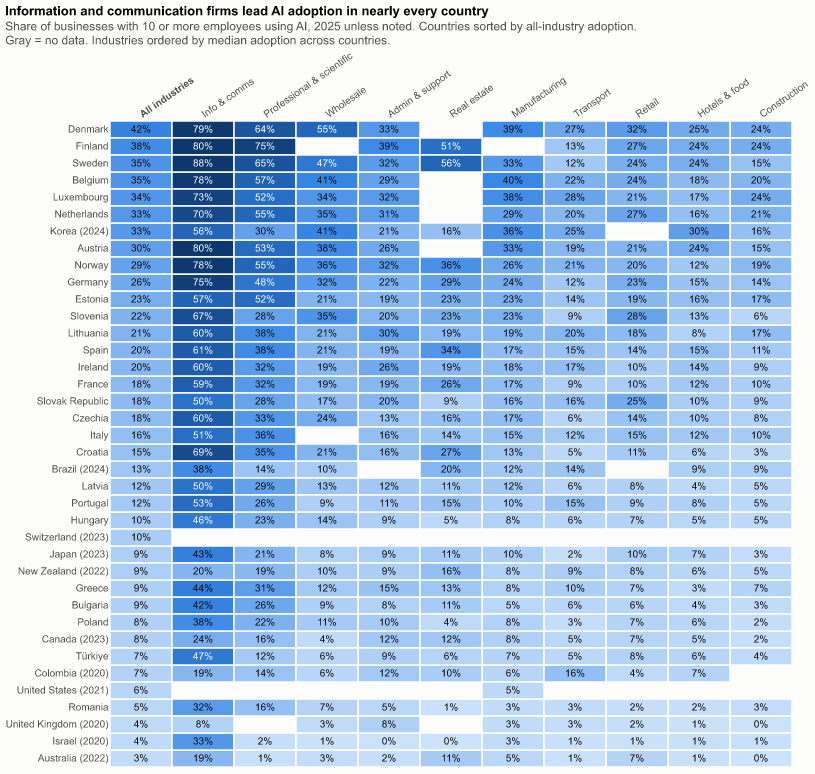

In [71]:
SHORT = {
    "Total - all activities": "All industries",
    "Information and communication": "Info & comms",
    "Professional, scientific and technical activities": "Professional & scientific",
    "Financial and insurance activities": "Finance & insurance",
    "Administrative and support service activities": "Admin & support",
    "Wholesale trade, except of motor vehicles and motorcycles": "Wholesale",
    "Retail trade, except of motor vehicles and motorcycles": "Retail",
    "Real estate activities": "Real estate",
    "Manufacturing": "Manufacturing",
    "Construction": "Construction",
    "Transportation and storage": "Transport",
    "Accommodation and food service activities": "Hotels & food",
}

ind = ai[(ai["size"] == SIZE) & ~ai["iso3"].str.startswith(("EU27", "OECD"))].dropna(subset=["share"]).copy()

# One year per country: the latest year with an all-industries figure
yr = ind[ind["activity"] == "Total - all activities"].groupby("iso3")["year"].max()
ind = ind[ind["year"] == ind["iso3"].map(yr)].copy()
ind_newest = yr.max()
ind["label"] = ind["country"].where(ind["year"] == ind_newest,
                                    ind["country"] + " (" + ind["year"].astype(str) + ")")
ind["industry"] = ind["activity"].map(SHORT)

# Drop industries reported by fewer than half the countries
coverage = ind.groupby("industry")["iso3"].nunique()
dropped = coverage[coverage < ind["iso3"].nunique() / 2].index.tolist()
print("Dropped for low coverage:", dropped)
ind = ind[~ind["industry"].isin(dropped)]

# Column order: All industries first, then by median adoption; rows by all-industries adoption
med = ind[ind["industry"] != "All industries"].groupby("industry")["share"].median()
col_order = ["All industries"] + med.sort_values(ascending=False).index.tolist()
row_order = (ind[ind["industry"] == "All industries"].sort_values("share", ascending=False)["label"].tolist())

# Full grid so missing cells show as gray
grid = (ind.pivot_table(index="label", columns="industry", values="share")
        .reset_index().melt(id_vars="label", var_name="industry", value_name="share"))

bold_total = {"condition": {"test": "datum.value == 'All industries'", "value": "bold"}, "value": "normal"}
base = alt.Chart(grid).encode(
    x=alt.X("industry:N", sort=col_order, title=None,
            axis=alt.Axis(orient="top", labelAngle=-35, labelAlign="left", labelBaseline="middle",
                          labelLimit=200, labelPadding=6, ticks=False, domain=False,
                          labelFontWeight=bold_total)),
    y=alt.Y("label:N", sort=row_order, title=None, axis=alt.Axis(ticks=False, domain=False)))

# Gray background for every cell, then colored cells only where there is data
background = base.mark_rect(color="#f0efeb", stroke="white", strokeWidth=1.5)
cells = base.transform_filter("isValid(datum.share)").mark_rect(stroke="white", strokeWidth=1.5).encode(
    color=alt.Color("share:Q", legend=None, scale=alt.Scale(range=BLUES, domain=[0, 0.8], clamp=True)))
text = base.transform_filter("isValid(datum.share)").mark_text(fontSize=10).encode(
    text=alt.Text("share:Q", format=".0%"),
    color=alt.condition("datum.share > 0.45", alt.value("white"), alt.value("#0b0b0b")))


industry_heatmap = (cells + text).properties(
    width=alt.Step(62), height=alt.Step(17),
    title=alt.Title(
        "Information and communication firms lead AI adoption in nearly every country",
        subtitle=[f"Share of businesses with {SIZE} employees using AI, {ind_newest} unless noted. "
                  "Countries sorted by all-industry adoption.",
                  "Gray = no data. Industries ordered by median adoption across countries."]))

industry_heatmap.save("figures/ai_by_industry.png", scale_factor=2)
industry_heatmap